# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**

Работа выполнена на собственной NVIDIA GeForce RTX 3080 с 10 ГБ памяти; квантизация проверена на CPU. Среда: Python 3.13.5, PyTorch 2.9.0+cu126, Transformers 5.22.1, Datasets 5.1.0. Финальный прогон выполнен с `FAST_MODE = False` и сохранёнными outputs.

Основная модель: [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), MIT. В сравнении использована [cointegrated/rubert-tiny](https://huggingface.co/cointegrated/rubert-tiny), MIT. Данные: русские сплиты [Babelscape/WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural), CC BY-NC-SA 4.0; 20 000 предложений train, 11 540 validation и 11 580 test. Ревизии обеих моделей и датасета зафиксированы полными SHA.

Выполнены задания 1.1, 1.2, 2.1, 2.2, 3.1, 4.1, 4.2, 5.1, 5.2, 5.3 и бонусы 6.1, 6.2, 6.3, 6.4, 6.5. Дополнительный тест содержит 60 синтетических предложений с явной разметкой, составленной ассистентом; файл: `artifacts/extra_annotations.jsonl`. Независимая человеческая проверка этой разметки не проводилась.

Источники: исходный шаблон задания; [статья WikiNEuRal](https://aclanthology.org/2021.findings-emnlp.215/); [описание rubert-tiny2 автором](https://habr.com/ru/articles/669674/); документация [Token classification](https://huggingface.co/docs/transformers/main/en/tasks/token_classification), [Trainer](https://huggingface.co/docs/transformers/main/en/main_classes/trainer), [динамической квантизации PyTorch](https://docs.pytorch.org/docs/2.9/generated/torch.ao.quantization.quantize_dynamic.html).

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q --use-pep517 --no-cache-dir "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

W1122 15:01:36.162000 41328 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.9.0+cu126, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda NVIDIA GeForce RTX 3080


In [4]:
FAST_MODE = False
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None
N_EVAL = 500 if FAST_MODE else None
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}
torch.set_num_threads(min(4, os.cpu_count() or 1))

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:**

Выбран [rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2), русский BERT под лицензией MIT: 3 слоя, hidden size 312, словарь 83 828 сабвордов и 29,098,929 параметров с NER-головой на 9 тегов. Он наследует rubert-tiny, обученный на Yandex Translate, OPUS-100 и Tatoeba, и дополнительно обучен на MLM, NLI и приближении эмбеддингов LaBSE; полный состав дополнительного корпуса в карточке не указан. Русский словарь и компактный энкодер подходят для WikiNEuRal и позволили получить test F1 0.8234 за 89.7 с обучения. [Карточка исходной tiny](https://huggingface.co/cointegrated/rubert-tiny), [описание дообучения tiny2](https://habr.com/ru/articles/669674/).

Альтернатива из списка: [DeepPavlov/rubert-base-cased](https://huggingface.co/DeepPavlov/rubert-base-cased), около 180 млн параметров, 12 слоёв и hidden size 768, предобучение на русской Википедии и новостях. По архитектуре он требует больше памяти и вычислений; его сопоставимых замеров скорости и NER-F1 на WikiNEuRal в карточке нет, поэтому преимущество качества здесь не утверждается. В собственном сравнении маленьких моделей tiny2 получил 0.8234, tiny: 0.7957 на одном test.

Без фиксированного `revision` обновление `main` может изменить веса, словарь и разбиение слов на сабворды: тогда изменятся выравнивание меток, формы параметров и метрики даже при том же seed; SHA фиксирует файлы модели, а версии библиотек закреплены отдельно.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    base = model.base_model
    embeddings = base.embeddings
    encoder = getattr(base, 'encoder', getattr(base, 'transformer', None))
    layers = getattr(encoder, 'layer', getattr(encoder, 'layers', None))
    if layers is None:
        raise ValueError('Не найдены слои энкодера')
    head = model.classifier
    groups = [embeddings, *layers, head]
    assigned = set()
    sizes = []
    for module in groups:
        parameters = {id(p): p for p in module.parameters() if id(p) not in assigned}
        sizes.append(sum(p.numel() for p in parameters.values()))
        assigned.update(parameters)
    other = sum(p.numel() for p in model.parameters() if id(p) not in assigned)
    return dict(embeddings=sizes[0], encoder=sum(sizes[1:-1]),
                head=sizes[-1], other=other, layers=sizes[1:-1])

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)
demo_shapes = {k: list(v.shape) for k, v in enc.items()}
demo_shapes['hidden_states'] = [list(h.shape) for h in out.hidden_states]
demo_shapes['logits'] = list(out.logits.shape)
print(json.dumps(demo_shapes, ensure_ascii=False, indent=2))

{
  "input_ids": [
    2,
    11
  ],
  "token_type_ids": [
    2,
    11
  ],
  "attention_mask": [
    2,
    11
  ],
  "hidden_states": [
    [
      2,
      11,
      312
    ],
    [
      2,
      11,
      312
    ],
    [
      2,
      11,
      312
    ],
    [
      2,
      11,
      312
    ]
  ],
  "logits": [
    2,
    11,
    7
  ]
}


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 4.6 ms на NVIDIA GeForce RTX 3080


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:**

Для двух предложений по 6 слов `input_ids` и `attention_mask` имеют форму `(2, 11)`: WordPiece добавил сабворды, специальные токены и padding. Эмбеддинги выдают `(2, 11, 312)`, каждый из трёх слоёв сохраняет эту форму; сохранены четыре `hidden_states`, включая выход эмбеддингов, а голова на 7 демонстрационных тегов выдаёт `logits (2, 11, 7)`.

В эмбеддингах 26,794,560 параметров из 29,098,303, то есть 92.1%: основной вклад даёт таблица `83828 × 312`, затем позиции и типы сегментов. В энкодере 2,301,552 параметров, по 767,184 на слой; в голове 2,191, в остальных блоках 0. Между токенами информация передаётся в attention слоёв энкодера; lookup эмбеддингов, FFN и линейная голова применяются к каждой позиции отдельно. После выбора тега первого сабворда BIO собирается в спаны слов, поэтому длина 11 в logits не означает 11 исходных слов.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'Babelscape/wikineural', None
DATASET_REVISION = '74c9b9dca034bb1606a6769457983904bd976803'
data_files = {
    split: f'hf://datasets/{DATASET_ID}@{DATASET_REVISION}/data/{name}-00000-of-00001.parquet'
    for split, name in [('train', 'train_ru'), ('validation', 'val_ru'), ('test', 'test_ru')]
}
raw = load_dataset('parquet', data_files=data_files)
source_sizes = {split: len(ds) for split, ds in raw.items()}
raw['train'] = raw['train'].shuffle(seed=SEED).select(range(20000))
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']
print('Исходные размеры:', source_sizes)
print('Выбранные размеры:', {split: len(ds) for split, ds in raw.items()})

Исходные размеры: {'train': 92320, 'validation': 11540, 'test': 11580}
Выбранные размеры: {'train': 20000, 'validation': 11540, 'test': 11580}


train {"sentences": 20000, "entities": {"LOC": 15132, "MISC": 5199, "ORG": 4428, "PER": 7107}, "sentence_lengths": {"count": 20000, "mean": 19.6183, "median": 17.0, "p95": 40.0, "maximum": 214}, "span_lengths": {"count": 31866, "mean": 1.3111780581183707, "median": 1.0, "p95": 3.0, "maximum": 24}, "per_type_lengths": {"LOC": {"count": 15132, "mean": 1.126222574676183, "median": 1.0, "p95": 2.0, "maximum": 9}, "MISC": {"count": 5199, "mean": 1.519715329871129, "median": 1.0, "p95": 4.0, "maximum": 24}, "ORG": {"count": 4428, "mean": 1.6203703703703705, "median": 1.0, "p95": 3.0, "maximum": 17}, "PER": {"count": 7107, "mean": 1.3597861263542985, "median": 1.0, "p95": 3.0, "maximum": 6}}, "unique_entity_surfaces": {"LOC": 7851, "MISC": 3783, "ORG": 2665, "PER": 5500}}


validation {"sentences": 11540, "entities": {"LOC": 8851, "MISC": 2642, "ORG": 2710, "PER": 4007}, "sentence_lengths": {"count": 11540, "mean": 18.78838821490468, "median": 17.0, "p95": 38.0, "maximum": 107}, "span_lengths": {"count": 18210, "mean": 1.3194398682042834, "median": 1.0, "p95": 3.0, "maximum": 10}, "per_type_lengths": {"LOC": {"count": 8851, "mean": 1.1041690204496668, "median": 1.0, "p95": 2.0, "maximum": 7}, "MISC": {"count": 2642, "mean": 1.5980317940953823, "median": 1.0, "p95": 4.0, "maximum": 9}, "ORG": {"count": 2710, "mean": 1.6645756457564576, "median": 1.0, "p95": 3.0, "maximum": 10}, "PER": {"count": 4007, "mean": 1.3778387821312703, "median": 1.0, "p95": 2.0, "maximum": 5}}, "unique_entity_surfaces": {"LOC": 4593, "MISC": 1946, "ORG": 1773, "PER": 3095}}


test {"sentences": 11580, "entities": {"LOC": 8596, "MISC": 2962, "ORG": 3051, "PER": 3489}, "sentence_lengths": {"count": 11580, "mean": 18.773056994818653, "median": 17.0, "p95": 38.0, "maximum": 124}, "span_lengths": {"count": 18098, "mean": 1.3563929715990717, "median": 1.0, "p95": 3.0, "maximum": 13}, "per_type_lengths": {"LOC": {"count": 8596, "mean": 1.1109818520241972, "median": 1.0, "p95": 2.0, "maximum": 7}, "MISC": {"count": 2962, "mean": 1.6951384199864956, "median": 1.0, "p95": 4.0, "maximum": 11}, "ORG": {"count": 3051, "mean": 1.662405768600459, "median": 1.0, "p95": 3.0, "maximum": 13}, "PER": {"count": 3489, "mean": 1.405846947549441, "median": 1.0, "p95": 2.0, "maximum": 5}}, "unique_entity_surfaces": {"LOC": 4454, "MISC": 2150, "ORG": 1920, "PER": 2809}}


Совпадающие предложения между сплитами: {'train/validation': 0, 'train/test': 0, 'validation/test': 0}


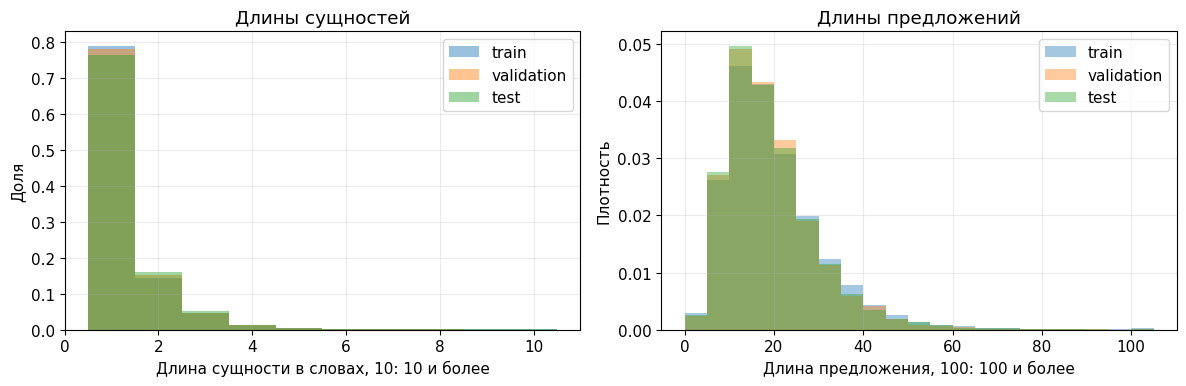

In [14]:
from seqeval.metrics.sequence_labeling import get_entities


def describe_lengths(values):
    return dict(count=len(values), mean=float(np.mean(values)), median=float(np.median(values)),
                p95=float(np.quantile(values, 0.95)), maximum=int(max(values)))


dataset_stats = {}
span_lengths_by_split = {}
sentence_lengths_by_split = {}
for split, ds in raw.items():
    counts = collections.Counter()
    span_lengths = []
    by_type = collections.defaultdict(list)
    surfaces = collections.defaultdict(set)
    sentence_lengths = []
    for ex in ds:
        assert len(ex['tokens']) == len(ex['ner_tags'])
        sentence_lengths.append(len(ex['tokens']))
        for typ, start, end in get_entities([LABEL_NAMES[i] for i in ex['ner_tags']]):
            counts[typ] += 1
            span_lengths.append(end - start + 1)
            by_type[typ].append(end - start + 1)
            surfaces[typ].add(tuple(ex['tokens'][start:end + 1]))
    dataset_stats[split] = dict(sentences=len(ds), entities=dict(sorted(counts.items())),
                               sentence_lengths=describe_lengths(sentence_lengths),
                               span_lengths=describe_lengths(span_lengths),
                               per_type_lengths={k: describe_lengths(v) for k, v in sorted(by_type.items())},
                               unique_entity_surfaces={k: len(v) for k, v in sorted(surfaces.items())})
    span_lengths_by_split[split] = span_lengths
    sentence_lengths_by_split[split] = sentence_lengths
    print(split, json.dumps(dataset_stats[split], ensure_ascii=False))

split_texts = {s: {tuple(ws) for ws in ds['tokens']} for s, ds in raw.items()}
split_overlap = {f'{a}/{b}': len(split_texts[a] & split_texts[b])
                 for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]}
print('Совпадающие предложения между сплитами:', split_overlap)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split in raw:
    lengths = np.asarray(span_lengths_by_split[split])
    axes[0].hist(np.minimum(lengths, 10), bins=np.arange(0.5, 11.5),
                 alpha=0.45, density=True, label=split)
    axes[1].hist(np.minimum(sentence_lengths_by_split[split], 100),
                 bins=np.arange(0, 106, 5), alpha=0.4, density=True, label=split)
axes[0].set(xlabel='Длина сущности в словах, 10: 10 и более', ylabel='Доля', title='Длины сущностей')
axes[1].set(xlabel='Длина предложения, 100: 100 и более', ylabel='Плотность', title='Длины предложений')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**

[WikiNEuRal](https://huggingface.co/datasets/Babelscape/wikineural) опубликован Babelscape под CC BY-NC-SA 4.0; тексты взяты из Википедии, разметка получена автоматически сочетанием методов на базе знаний, нейросетей и адаптации домена, поэтому это silver-разметка. [Описание метода](https://aclanthology.org/2021.findings-emnlp.215/). Из 92 320 предложений `train_ru` выбраны 20 000 через `shuffle(seed=0)` из-за бюджета нескольких экспериментов; исходные `val_ru` и `test_ru` использованы полностью: 11 540 и 11 580 предложений. Точных совпадений предложений между сплитами нет.

| Тип | train | validation | test |
|---|---:|---:|---:|
| LOC | 15132 | 8851 | 8596 |
| MISC | 5199 | 2642 | 2962 |
| ORG | 4428 | 2710 | 3051 |
| PER | 7107 | 4007 | 3489 |

В train редчайший тип: ORG, 4428 сущностей; LOC встречается в 3.42 раза чаще. Средняя длина предложения train составляет 19.62 слова, 95-й процентиль: 40, максимум: 214; у спанов средняя длина 1.31, медиана 1, 95-й процентиль 3, максимум 24 слова. Для ORG и MISC средние длины равны 1.62 и 1.52 слова против 1.13 для LOC: длинные названия усложняют точное совпадение границ, а дисбаланс и автоматическая разметка влияют на обучение и интерпретацию ошибок.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    spans = []
    start = None
    current_type = None
    for index, tag in enumerate(list(tags) + ['O']):
        if tag == 'O':
            prefix, typ = 'O', None
        else:
            prefix, sep, typ = tag.partition('-')
            if prefix not in {'B', 'I'} or not sep or not typ:
                raise ValueError(f'Некорректный BIO-тег: {tag}')
        continues = prefix == 'I' and start is not None and typ == current_type
        if start is not None and not continues:
            spans.append((start, index, current_type))
            start, current_type = None, None
        if prefix != 'O' and not continues:
            start, current_type = index, typ
    return spans


def spans_to_bio(spans, n_words):
    if n_words < 0:
        raise ValueError('Число слов должно быть неотрицательным')
    tags = ['O'] * n_words
    for start, end, typ in sorted(spans):
        if not 0 <= start < end <= n_words or not typ:
            raise ValueError('Некорректные границы или тип спана')
        if any(tag != 'O' for tag in tags[start:end]):
            raise ValueError('BIO не поддерживает пересекающиеся спаны')
        tags[start:end] = ['B-' + typ] + ['I-' + typ] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    aligned = []
    seen = set()
    for word_id in word_ids:
        if word_id is None:
            aligned.append(-100)
            continue
        if not 0 <= word_id < len(word_labels):
            raise ValueError('Номер слова вне разметки')
        label = word_labels[word_id]
        if word_id not in seen:
            aligned.append(label)
        elif b_to_i is None:
            aligned.append(-100)
        else:
            aligned.append(b_to_i.get(label, label))
        seen.add(word_id)
    return aligned

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
Path('data').mkdir(exist_ok=True)
conversion_stats = {}
for split, ds in raw.items():
    path = Path('data') / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as stream:
        for ex in ds:
            spans = bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
            stream.write(json.dumps(dict(tokens=ex['tokens'], spans=spans), ensure_ascii=False) + '\n')
    changed = 0
    checked = 0
    with path.open(encoding='utf-8') as stream:
        for original, line in zip(ds, stream, strict=True):
            restored = json.loads(line)
            expected = [LABEL_NAMES[i] for i in original['ner_tags']]
            got = spans_to_bio(restored['spans'], len(restored['tokens']))
            assert restored['tokens'] == original['tokens']
            assert bio_to_spans(expected) == bio_to_spans(got)
            changed += got != expected
            checked += 1
    conversion_stats[split] = dict(checked=checked, noncanonical_bio=changed)
    print(split, conversion_stats[split])
for ex in raw['train'].select(range(3)):
    tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
    print('Предложение:', ' '.join(ex['tokens']))
    print('Спаны:', [(s, e, t, ' '.join(ex['tokens'][s:e])) for s, e, t in bio_to_spans(tags)])
    print('BIO:', list(zip(ex['tokens'], tags)))

train {'checked': 20000, 'noncanonical_bio': 682}


validation {'checked': 11540, 'noncanonical_bio': 393}


test {'checked': 11580, 'noncanonical_bio': 464}
Предложение: Работы по строительству первоначальной инфраструктуры аэропорта начались в 1937 году на месте девяти сельскохозяйственных угодий , выкупленных муниципальным комитетом Торонто у частных владельцев .
Спаны: [(19, 20, 'LOC', 'Торонто')]
BIO: [('Работы', 'O'), ('по', 'O'), ('строительству', 'O'), ('первоначальной', 'O'), ('инфраструктуры', 'O'), ('аэропорта', 'O'), ('начались', 'O'), ('в', 'O'), ('1937', 'O'), ('году', 'O'), ('на', 'O'), ('месте', 'O'), ('девяти', 'O'), ('сельскохозяйственных', 'O'), ('угодий', 'O'), (',', 'O'), ('выкупленных', 'O'), ('муниципальным', 'O'), ('комитетом', 'O'), ('Торонто', 'B-LOC'), ('у', 'O'), ('частных', 'O'), ('владельцев', 'O'), ('.', 'O')]
Предложение: Карьеру профессионального футболиста начинал на позиции полузащитника в скромном « Клайде » .
Спаны: [(9, 12, 'ORG', '« Клайде »')]
BIO: [('Карьеру', 'O'), ('профессионального', 'O'), ('футболиста', 'O'), ('начинал', 'O'), ('на', 'O'), ('позиц

In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 20000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11540
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'lang'],
        num_rows: 11580
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']


train: проверено 19981 предложений, обрезано по MAX_LENGTH 20, слов без сабвордов или за обрезкой 455
[CLS]            None  -100
Работы              0  O
по                  1  O
строительству       2  O
первоначальной      3  O
инфраструктуры      4  O
аэропорта           5  O
начались            6  O
в                   7  O
1937                8  O
году                9  O
на                 10  O
месте              11  O
девяти             12  O
сельскохозяйственных   13  O
угодий             14  O
,                  15  O
выкуп              16  O
##ленных           16  -100
муниципальным      17  O
комитетом          18  O
Торонто            19  B-LOC
у                  20  O
частных            21  O
владельцев         22  O
.                  23  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Метка только на первом сабворде даёт каждому исходному слову один вклад в cross-entropy; иначе длинные слова с большим числом частей получили бы больший вес. Значение `-100` исключает продолжения слова и специальные токены из loss, но attention по их представлениям сохраняется.

В train 20 последовательностей достигли длины 128: у одной исходная длина ровно 128, остальные 19 действительно обрезаны; потеряно 455 слов за лимитом, слов без сабвордов до усечения нет. В 19981 предложении восстановлены все слова. Счётчик шаблона проверяет равенство длины лимиту, поэтому он включает и вход без потери слов. При оценке отсутствующим словам назначается `O`, что может уменьшить recall и испортить границу сущности на краю входа.

Обратная конвертация BIO → JSON-спаны → BIO проверена на 43,120 предложениях; неканонический BIO найден в 1539 предложениях: train 682, validation 393, test 464. Например, «Гран-при» в третьем показанном предложении размечено одиночным `I-MISC`; при обратной конвертации оно становится `B-MISC`, но спан сохраняется, как в seqeval. Пересекающихся и вложенных спанов в этом плоском BIO-представлении нет, восстановление границ прошло без расхождений; для обучения сохранены исходные метки.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    return {word: max(counter, key=lambda tag: (counter[tag], tag == 'O', tag))
            for word, counter in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
majority_tagger = fit_majority_tagger(data['train']['tokens'], train_tags)
majority_pred = [predict_majority(majority_tagger, words) for words in val_tokens]
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline = dict(majority=entity_scores(val_gold, majority_pred),
                random_head=entity_scores(val_gold, random_pred))
entity_word_count = sum(tag != 'O' for tags in val_gold for tag in tags)
known_entity_word_count = sum(word in majority_tagger and tag != 'O'
                              for words, tags in zip(val_tokens, val_gold)
                              for word, tag in zip(words, tags))
baseline_details = dict(known_entity_words=known_entity_word_count, entity_words=entity_word_count,
                        random_tag_counts=dict(collections.Counter(tag for tags in random_pred for tag in tags)))
print(json.dumps(baseline, ensure_ascii=False, indent=2))
print(json.dumps(baseline_details, ensure_ascii=False))
random_model.cpu()
del random_model
if device.type == 'cuda':
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{
  "majority": {
    "f1_micro": 0.49554033739769493,
    "f1_macro": 0.4199065672873253,
    "precision": 0.6325799573560767,
    "recall": 0.4073036792970895
  },
  "random_head": {
    "f1_micro": 0.029393424222334538,
    "f1_macro": 0.028270139891322568,
    "precision": 0.016691889635223688,
    "recall": 0.12295442064799561
  }
}
{"known_entity_words": 14539, "entity_words": 24027, "random_tag_counts": {"O": 46258, "B-LOC": 19758, "I-PER": 53044, "I-ORG": 13943, "I-LOC": 12004, "B-PER": 38401, "I-MISC": 16478, "B-ORG": 11557, "B-MISC": 5375}}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

Словарный бейзлайн на validation получил entity micro-F1 0.4955, precision 0.6326 и recall 0.4073: повторяющиеся названия запоминаются, но словарь не учитывает контекст, морфологические варианты и границы многословных сущностей. В train встречались 14539 из 24027 слов validation, размеченных как сущности, то есть 60.5%; это ограничивает покрытие словаря.

У энкодера со случайной головой F1 0.0294, precision 0.0167, recall 0.1230; среди предсказаний преобладает `I-PER` (53044 слов), встречаются все 9 тегов. Предобучение дало языковые представления, но случайные веса классификатора ещё не связывают их с BIO-классами: возникают неверные типы, границы и множество ложных спанов.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    tok = tok or tokenizer
    for parameter in model.parameters():
        parameter.requires_grad_(True)
    if freeze_encoder:
        for parameter in model.base_model.parameters():
            parameter.requires_grad_(False)
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    interval = max(1, total_steps // 12)
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=64,
        warmup_steps=math.ceil(total_steps * 0.1), weight_decay=0.01,
        lr_scheduler_type='linear', optim='adamw_torch', max_grad_norm=1.0,
        fp16=device.type == 'cuda', bf16=False,
        eval_strategy='steps', eval_steps=interval, logging_steps=interval,
        logging_first_step=True, save_strategy='no', report_to='none',
        prediction_loss_only=True, disable_tqdm=True,
        seed=SEED, data_seed=SEED, dataloader_num_workers=0,
        dataloader_pin_memory=device.type == 'cuda')
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      processing_class=tok, data_collator=DataCollatorForTokenClassification(tok))
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    trainer.train()
    trainer.evaluate()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    return copy.deepcopy(trainer.state.log_history), seconds

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '2.106', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.0016'}


{'loss': '0.6183', 'grad_norm': '0.732', 'learning_rate': '0.0001638', 'epoch': '0.2496'}


{'eval_loss': '0.161', 'eval_runtime': '2.5', 'eval_samples_per_second': '4616', 'eval_steps_per_second': '72.4', 'epoch': '0.2496'}


{'loss': '0.1277', 'grad_norm': '1.26', 'learning_rate': '0.0001855', 'epoch': '0.4992'}


{'eval_loss': '0.1048', 'eval_runtime': '2.512', 'eval_samples_per_second': '4594', 'eval_steps_per_second': '72.06', 'epoch': '0.4992'}


... (18 outputs left out)

{'loss': '0.0261', 'grad_norm': '0.3914', 'learning_rate': '5.928e-07', 'epoch': '2.995'}


{'eval_loss': '0.08135', 'eval_runtime': '2.719', 'eval_samples_per_second': '4245', 'eval_steps_per_second': '66.58', 'epoch': '2.995'}


{'eval_loss': '0.08134', 'eval_runtime': '2.518', 'eval_samples_per_second': '4583', 'eval_steps_per_second': '71.89', 'epoch': '3'}
{'train_runtime': '87.1', 'train_samples_per_second': '688.9', 'train_steps_per_second': '21.53', 'train_loss': '0.105', 'epoch': '3'}


{'eval_loss': '0.08134', 'eval_runtime': '2.428', 'eval_samples_per_second': '4753', 'eval_steps_per_second': '74.54', 'epoch': '3'}
обучение: 89.7 c на NVIDIA GeForce RTX 3080, 20000 предложений, 3 эпох(а)


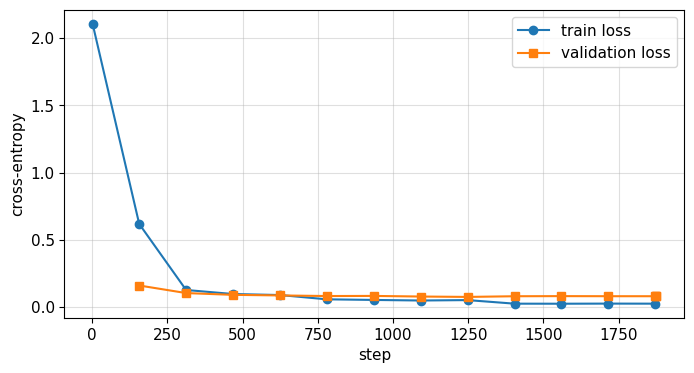

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

Для компактной модели использованы AdamW, `lr=2e-4`, batch size 32, 3 эпохи, warmup 188 из 1875 шагов, линейное снижение learning rate, weight decay 0.01 и FP16 на GPU. Такая скорость обучения адаптирует небольшую модель и новую голову, warmup смягчает первые обновления, weight decay ограничивает рост весов, а batch 32 помещается в 10 ГБ памяти.

Train loss изменился с 2.1057 до 0.0261; минимум validation loss 0.0762 достигнут на шаге 1248, итоговый loss: 0.0813. После минимума validation loss вырос на 0.0052: есть признак начавшегося переобучения. Кривые не дают оснований увеличивать число эпох: лучшая оценка loss получена примерно после двух эпох. Обучение вместе с регулярной оценкой validation заняло 89.7 с на NVIDIA GeForce RTX 3080; сохранено 14 оценок validation loss.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    true_positive = predicted = relevant = 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for gold_tag, pred_tag in zip(gold_tags, pred_tags, strict=True):
            relevant += gold_tag != 'O'
            predicted += pred_tag != 'O'
            true_positive += pred_tag != 'O' and pred_tag == gold_tag
    return 2 * true_positive / (predicted + relevant) if predicted + relevant else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0


test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)
validation = entity_scores(val_gold, val_pred)
validation['token_f1'] = token_f1(val_gold, val_pred)
final = entity_scores(test_gold, test_pred)
final['token_f1'] = token_f1(test_gold, test_pred)
test_report = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final['per_type'] = {typ: test_report[typ] for typ in ENTITY_TYPES}
for name, gold_tags, pred_tags, scores in [('validation', val_gold, val_pred, validation),
                                          ('test', test_gold, test_pred, final)]:
    print(name)
    print(classification_report(gold_tags, pred_tags, digits=4, zero_division=0))
    print('F1 по словам:', round(token_f1(gold_tags, pred_tags), 6))

validation


              precision    recall  f1-score   support

         LOC     0.8870    0.9002    0.8936      8851
        MISC     0.6645    0.6696    0.6670      2642
         ORG     0.6595    0.7125    0.6850      2710
         PER     0.8231    0.8757    0.8486      4007

   micro avg     0.8057    0.8334    0.8194     18210
   macro avg     0.7585    0.7895    0.7736     18210
weighted avg     0.8068    0.8334    0.8198     18210

F1 по словам: 0.836441
test


              precision    recall  f1-score   support

         LOC     0.8950    0.9080    0.9014      8596
        MISC     0.6871    0.6894    0.6882      2962
         ORG     0.6774    0.7345    0.7048      3051
         PER     0.8175    0.8882    0.8514      3489

   micro avg     0.8082    0.8392    0.8234     18098
   macro avg     0.7692    0.8050    0.7865     18098
weighted avg     0.8093    0.8392    0.8237     18098

F1 по словам: 0.841821


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

Хуже всего на test распознаётся MISC: precision 0.6871, recall 0.6894, F1 0.6882, support 2962. В train для этого типа 5199 примеров и 3783 разных написаний, средняя длина спана 1.52 слова: редкие и разнообразные названия затрудняют перенос, а ошибки границ особенно заметны при точном совпадении.

Micro-F1 0.8234, macro-F1 0.7865; разность 0.0369 связана с тем, что micro сильнее определяется частым LOC, а macro даёт всем четырём типам одинаковый вес. Токенный F1 0.8418, он выше entity-F1 на 0.0185. Частично верная сущность приносит верные слова, хотя весь спан не засчитывается; кроме того, слова и сущности имеют разные веса. Для извлечения готовых имён, организаций и мест пользователю ближе entity-F1, который проверяет весь фрагмент вместе с типом.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    gold_spans, pred_spans = list(gold_spans), list(pred_spans)
    result = []
    for gold_span in gold_spans:
        start, end, typ = gold_span
        overlapping = [span for span in pred_spans if max(start, span[0]) < min(end, span[1])]
        if gold_span in pred_spans:
            result.append(('correct', gold_span, gold_span))
            continue
        same_type = [span for span in overlapping if span[2] == typ]
        candidates = same_type or overlapping
        if candidates:
            chosen = max(candidates, key=lambda span: (min(end, span[1]) - max(start, span[0]),
                                                       -abs(start - span[0]) - abs(end - span[1])))
            result.append(('boundary' if same_type else 'type', gold_span, chosen))
        else:
            result.append(('missed', gold_span, None))
    for pred_span in pred_spans:
        if not any(max(pred_span[0], gold_span[0]) < min(pred_span[1], gold_span[1]) for gold_span in gold_spans):
            result.append(('spurious', None, pred_span))
    return result

Количество: {'correct': 15177, 'boundary': 902, 'type': 1688, 'missed': 443, 'spurious': 807}
Доли среди ошибок: {'boundary': 0.2349, 'type': 0.4396, 'missed': 0.1154, 'spurious': 0.2102}
boundary предложение 0 : Тем не менее , он должен был остаться на своем посту Председателя МПЛА и , следовательно , продолжать играть ключевую роль в ангольской политике под руководством правящей партии .
gold_span (12, 13, 'ORG') МПЛА
pred_span (11, 13, 'ORG') Председателя МПЛА
boundary предложение 85 : Реинкарнация Сыма И , стратега Цао Цао .
gold_span (1, 3, 'PER') Сыма И
pred_span (2, 3, 'PER') И
type предложение 21 : Веспремским епископам издавна принадлежала привилегия короновать венгерских королев , из-за чего Веспрем называли « городом королев » .
gold_span (11, 12, 'LOC') Веспрем
pred_span (11, 12, 'PER') Веспрем
type предложение 22 : В 1001 году в городе был построен собор святого Михаила , впоследствии неоднократно перестроенный .
gold_span (7, 10, 'LOC') собор святого Михаила
pred_span (9,

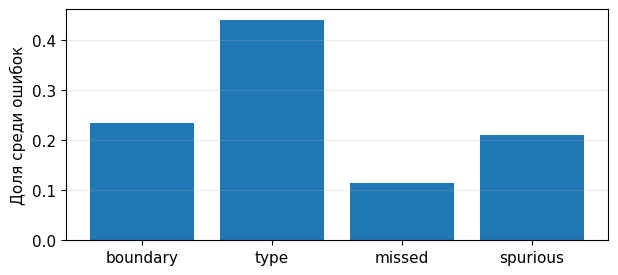

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются


errors = dict.fromkeys(ERROR_CATEGORIES, 0)
error_examples = collections.defaultdict(list)
for sentence_id, (words, gold_tags, pred_tags) in enumerate(zip(val_tokens, val_gold, val_pred)):
    for category, gold_span, pred_span in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        errors[category] += 1
        if category != 'correct' and len(error_examples[category]) < 5:
            error_examples[category].append(dict(sentence_id=sentence_id, tokens=words,
                                                  gold_span=gold_span, pred_span=pred_span))
error_total = sum(v for k, v in errors.items() if k != 'correct')
error_shares = {k: v / error_total if error_total else 0.0 for k, v in errors.items() if k != 'correct'}
print('Количество:', errors)
print('Доли среди ошибок:', {k: round(v, 4) for k, v in error_shares.items()})
for category in ERROR_CATEGORIES[1:]:
    for item in error_examples[category][:2]:
        words = item['tokens']
        print(category, 'предложение', item['sentence_id'], ':', ' '.join(words))
        for key in ['gold_span', 'pred_span']:
            span = item[key]
            print(key, span, ' '.join(words[span[0]:span[1]]) if span else None)
plt.figure(figsize=(7, 3))
plt.bar(list(error_shares), list(error_shares.values()))
plt.ylabel('Доля среди ошибок')
plt.grid(axis='y', alpha=0.25)
plt.show()

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

Самая частая категория: `type`, 1688 из 3840 ошибок, или 43.96%; далее `boundary`: 902 (23.49%), `spurious`: 807 (21.02%), `missed`: 443 (11.54%). Правильно найдены 15177 истинных спанов.

В ошибках типа название города «Веспрем» принято за PER, а из LOC «собор святого Михаила» выделен PER «Михаила»: одного сходства с личным именем оказалось недостаточно для учёта контекста. Ошибки границ включают присоединение должности в «Председателя МПЛА» и потерю части имени «Сыма И»; пропуски повторяются у «Веспрем», которого нет в выбранном train. Ложные спаны «жаркое» как MISC и «Водном» как LOC показывают избыточное срабатывание на обычных словах и фрагментах названий.

Среди сохранённых ошибок есть дефект эталона: в предложении 125 «Молекулярная масса F-фактора равна 45 Да» единица массы «Да» размечена как LOC, и её корректное отбрасывание моделью засчитано как `missed`. Дополнительная проверка исходной validation обнаружила `NaOH` как ORG в предложении 5161 и единицу расстояния «Мпк» как MISC в предложениях 1461 и 1484. Метрики выше рассчитаны по исходной разметке, поэтому они смешивают ошибки модели и эталона. Для уменьшения частой ошибки типа обоснованы проверка автоматически размеченных ORG/MISC и дополнительные контекстные примеры различения личных имён, географии и названных в честь людей объектов; эффект этих изменений в данном эксперименте не измерен.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'
model.cpu()
if device.type == 'cuda':
    torch.cuda.empty_cache()
set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(frozen_model, tokenized['train'], tokenized['validation'],
                                           freeze_encoder=True, out_dir='runs/freeze')
frozen_pred = predict_word_tags(frozen_model, val_tokens)
ablation = dict(setting=ABLATION, split='validation', seed=SEED,
                full=dict(**validation, seconds=train_seconds,
                          trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)),
                freeze=dict(**entity_scores(val_gold, frozen_pred), seconds=frozen_seconds,
                            trainable_params=sum(p.numel() for p in frozen_model.parameters() if p.requires_grad)))
RUN_TIMES['train_freeze_sec'] = frozen_seconds
print(json.dumps(ablation, ensure_ascii=False, indent=2))
frozen_model.cpu()
del frozen_model
if device.type == 'cuda':
    torch.cuda.empty_cache()
model.to(device)

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '2.106', 'grad_norm': 'inf', 'learning_rate': '0', 'epoch': '0.0016'}


{'loss': '1.649', 'grad_norm': '2.637', 'learning_rate': '0.0001638', 'epoch': '0.2496'}


{'eval_loss': '0.8789', 'eval_runtime': '2.473', 'eval_samples_per_second': '4667', 'eval_steps_per_second': '73.2', 'epoch': '0.2496'}


{'loss': '0.5046', 'grad_norm': '0.3975', 'learning_rate': '0.0001855', 'epoch': '0.4992'}


{'eval_loss': '0.3636', 'eval_runtime': '2.356', 'eval_samples_per_second': '4897', 'eval_steps_per_second': '76.81', 'epoch': '0.4992'}


... (20 outputs left out)

{'eval_loss': '0.2051', 'eval_runtime': '1.921', 'eval_samples_per_second': '6006', 'eval_steps_per_second': '94.2', 'epoch': '3'}
{'train_runtime': '57.15', 'train_samples_per_second': '1050', 'train_steps_per_second': '32.81', 'train_loss': '0.387', 'epoch': '3'}


{'eval_loss': '0.2051', 'eval_runtime': '2.156', 'eval_samples_per_second': '5353', 'eval_steps_per_second': '83.96', 'epoch': '3'}


{
  "setting": "freeze",
  "split": "validation",
  "seed": 0,
  "full": {
    "f1_micro": 0.8193597149489824,
    "f1_macro": 0.7735554808038516,
    "precision": 0.8057443193884052,
    "recall": 0.8334431630971993,
    "token_f1": 0.8364414171200731,
    "seconds": 89.72453290002886,
    "trainable_params": 29098929
  },
  "freeze": {
    "f1_micro": 0.5432016075016745,
    "f1_macro": 0.4055748796464641,
    "precision": 0.5522642151855635,
    "recall": 0.5344316309719934,
    "seconds": 59.533292899955995,
    "trainable_params": 2817
  }
}


BertForTokenClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(83828, 312, padding_idx=0)
      (position_embeddings): Embedding(2048, 312)
      (token_type_embeddings): Embedding(2, 312)
      (LayerNorm): LayerNorm((312,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-2): 3 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=312, out_features=312, bias=True)
              (key): Linear(in_features=312, out_features=312, bias=True)
              (value): Linear(in_features=312, out_features=312, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=312, out_features=312, bias=True)
              (LayerNorm): LayerNorm((312,), eps=1e-12, ele

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**

При замораживании энкодера validation micro-F1 изменился с 0.8194 до 0.5432, то есть на -27.62 п.п.; время изменилось с 89.7 до 59.5 с. Число обучаемых параметров уменьшилось с 29,098,929 до 2,817: обновлялась только линейная голова на 9 тегов.

Неадаптированные признаки предобучения хуже разделяют типы и границы WikiNEuRal, а отсутствие backward через энкодер сокращает вычисления. Все остальные настройки и инициализация головы совпадают; однако один seed и общий learning rate не дают оценки лучшего возможного качества замороженного варианта. Для более надёжного вывода нужны несколько seed и отдельный подбор learning rate головы по validation.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

Полное дообучение rubert-tiny2 на 20 000 предложений за 89.7 с дало validation micro-F1 0.8194, тогда как словарь получил 0.4955, а случайная голова 0.0294. На test entity micro-F1 составил 0.8234, macro-F1: 0.7865, токенный F1: 0.8418. Наиболее слабым типом оказался MISC с F1 0.6882, что согласуется с разнообразием названий и ошибками границ. Заморозка энкодера снизила validation F1 до 0.5432, поэтому в этом режиме одной головы оказалось недостаточно. Среди ошибок чаще всего встречается категория type, её доля составляет 44.0%. Основные ограничения результата: автоматическая разметка, использование 20 000 из 92 320 обучающих предложений, один seed и 455 потерянных слов train при ограничении 128 сабвордов. Следующий обоснованный эксперимент: проверка шумной разметки и добавление примеров слабого типа с оценкой по нескольким seed и неизменному test.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "Babelscape/wikineural", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 20000, "n_val": 11540, "n_test": 11580, "params_total": 29098929, "ablation": {"setting": "freeze", "split": "validation", "seed": 0, "full": {"f1_micro": 0.8193597149489824, "f1_macro": 0.7735554808038516, "precision": 0.8057443193884052, "recall": 0.8334431630971993, "token_f1": 0.8364414171200731, "seconds": 89.72453290002886, "trainable_params": 29098929}, "freeze": {"f1_micro": 0.543201607501
final F1 micro 0.8234


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    annotated_sentences = ['[PER:Анна Смирнова] приехала из [LOC:Казани] на конференцию.', 'Редактор [PER:Павел Орлов] встретился с коллегами в [LOC:Томске].', '[PER:Мария Иванова] представила доклад в [ORG:МГУ].', '[PER:Алексей Петров] отправил заявление в [ORG:Яндекс].', 'На выставке в [LOC:Самаре] выступила [PER:Елена Волкова].', '[PER:Дмитрий Соколов] вернулся в [LOC:Нижний Новгород] вечером.', '[PER:Ольга Кузнецова] работает в [ORG:Российской академии наук].', 'Писатель [PER:Иван Бунин] родился в [LOC:Воронеже].', '[PER:Юрий Гагарин] совершил полёт на корабле [MISC:Восток-1].', '[PER:Сергей Королёв] учился в [LOC:Москве].', 'Поезд из [LOC:Санкт-Петербурга] прибыл в [LOC:Великий Новгород].', 'Экспедиция пересекла [LOC:Уральские горы] и достигла [LOC:Байкала].', 'Между [LOC:Россией] и [LOC:Казахстаном] открыли новый маршрут.', 'Путешественники остановились на берегу [LOC:Белого моря].', 'Река [LOC:Волга] впадает в [LOC:Каспийское море].', 'Самолёт вылетел из [LOC:Нью-Йорка] в [LOC:Париж].', 'На [LOC:Дальнем Востоке] начался снегопад.', 'Порт расположен в [LOC:Ростове-на-Дону].', 'Студенты приехали в [LOC:Йошкар-Олу] на практику.', 'Автобус следует через [LOC:Петропавловск-Камчатский].', '[ORG:Сбербанк] открыл отделение в [LOC:Омске].', '[ORG:Газпром] опубликовал годовой отчёт.', '[ORG:Роскосмос] сообщил о запуске спутника.', 'Делегация [ORG:ООН] посетила [LOC:Женеву].', '[ORG:Московский государственный университет] объявил набор студентов.', '[ORG:Российские железные дороги] изменили расписание поездов.', 'Исследователи [ORG:Высшей школы экономики] представили результаты опроса.', 'Компания [ORG:Microsoft] провела презентацию в [LOC:Берлине].', 'Издательство [ORG:Эксмо] выпустило сборник рассказов.', '[ORG:Футбольный клуб Зенит] провёл тренировку в [LOC:Санкт-Петербурге].', 'В библиотеке обсуждали роман [MISC:Война и мир].', 'На экране показали фильм [MISC:Солярис] режиссёра [PER:Андрея Тарковского].', 'Школьники прочитали повесть [MISC:Капитанская дочка].', '[PER:Александр Пушкин] написал роман [MISC:Евгений Онегин].', 'Учёный получил [MISC:Нобелевскую премию] по физике.', 'В музее выставили картину [MISC:Девятый вал].', 'Оркестр исполнил балет [MISC:Лебединое озеро].', 'Преподаватель рекомендовал прочитать [MISC:Мастера и Маргариту].', 'В программе фестиваля был фильм [MISC:Иваново детство].', 'Посетители рассматривали картину [MISC:Утро в сосновом лесу].', '[ORG:Банк России] опубликовал заявление в [LOC:Москве].', 'Корреспондент [ORG:ТАСС] поговорил с [PER:Натальей Морозовой].', '[PER:Лев Толстой] жил в [LOC:Ясной Поляне].', 'Сотрудники [ORG:Института русского языка] приехали в [LOC:Псков].', '[PER:Антон Чехов] написал пьесу [MISC:Вишнёвый сад].', 'Профессор [PER:Ли Вэй] выступил в [ORG:СПбГУ].', '[PER:Жан-Поль Бельмондо] родился во [LOC:Франции].', '[ORG:Большой театр] показал оперу [MISC:Борис Годунов].', '[ORG:Национальный исследовательский университет ИТМО] находится в [LOC:Санкт-Петербурге].', '[PER:Фёдор Достоевский] написал роман [MISC:Преступление и наказание].', 'Сегодня студенты обсуждали результаты эксперимента.', 'Редактор вернул рукопись автору после проверки.', 'В воскресенье библиотека открывается в десять часов.', 'На улице шёл дождь, поэтому встречу перенесли.', 'Вчера команда завершила тестирование программы.', 'Сотрудники банка подготовили новый отчёт.', 'Городской музей закрылся на реконструкцию.', 'Поезд прибыл на станцию без опоздания.', 'Учитель попросил учеников открыть учебники.', 'После лекции слушатели задали несколько вопросов.']
    annotation_instructions = {
        'PER': 'Имена людей вместе с фамилией и отчеством; должность не входит в спан.',
        'ORG': 'Полное собственное название организации; родовое слово входит только в официальное название.',
        'LOC': 'Географические названия целиком; предлоги не входят в спан.',
        'MISC': 'Названия произведений, наград и именованных изделий; кавычки и родовое слово вне названия исключены.',
        'general': 'Плоские непересекающиеся спаны; сохраняется внешнее название. Токенизация отделяет пунктуацию, дефис внутри слова сохраняется.'
    }
    annotation_started = time.perf_counter()
    annotation_records = []
    word_pattern = r"\w+(?:-\w+)*|[^\w\s]"
    entity_pattern = re.compile(r'\[(PER|ORG|LOC|MISC):([^\]]+)\]')
    for index, text in enumerate(annotated_sentences):
        words, spans, last = [], [], 0
        for match in entity_pattern.finditer(text):
            words.extend(re.findall(word_pattern, text[last:match.start()]))
            entity_words = re.findall(word_pattern, match.group(2))
            start = len(words)
            words.extend(entity_words)
            spans.append((start, len(words), match.group(1)))
            last = match.end()
        words.extend(re.findall(word_pattern, text[last:]))
        tags = spans_to_bio(spans, len(words))
        assert bio_to_spans(tags) == spans
        assert tuple(words) not in set.union(*split_texts.values())
        annotation_records.append(dict(id=f'custom-{index:03d}', tokens=words,
                                       ner_tags=[label2id[tag] for tag in tags],
                                       source='synthetic_explicit_annotation_by_assistant'))
    assert len(annotation_records) >= 50
    assert len({tuple(row['tokens']) for row in annotation_records}) == len(annotation_records)
    annotation_path = ARTIFACTS / 'extra_annotations.jsonl'
    annotation_path.write_text(''.join(json.dumps(row, ensure_ascii=False) + '\n' for row in annotation_records), encoding='utf-8')
    restored_annotations = [json.loads(line) for line in annotation_path.read_text(encoding='utf-8').splitlines()]
    assert restored_annotations == annotation_records
    annotation_processing_seconds = time.perf_counter() - annotation_started
    manual_test = datasets.Dataset.from_list(restored_annotations)
    manual_gold = [[LABEL_NAMES[i] for i in row['ner_tags']] for row in restored_annotations]
    manual_pred = predict_word_tags(model, manual_test['tokens'])
    manual_scores = entity_scores(manual_gold, manual_pred)
    manual_counts = collections.Counter(typ for tags in manual_gold for _, _, typ in bio_to_spans(tags))
    annotation_results = dict(n_sentences=len(manual_test), entity_counts=dict(manual_counts),
                              negative_sentences=sum(all(t == 'O' for t in tags) for tags in manual_gold),
                              split='separate_synthetic_test', original_test_f1=final['f1_micro'],
                              new_test=manual_scores, delta_f1=manual_scores['f1_micro'] - final['f1_micro'],
                              processing_seconds=annotation_processing_seconds,
                              human_annotation_seconds=None, construction_seconds=None,
                              provenance='Тексты и явная разметка составлены ассистентом; независимой человеческой проверки нет.',
                              instructions=annotation_instructions)
    print(json.dumps(annotation_results, ensure_ascii=False, indent=2))
    print(classification_report(manual_gold, manual_pred, digits=4, zero_division=0))
    for row, pred_tags in list(zip(restored_annotations, manual_pred))[:5]:
        print(' '.join(row['tokens']))
        print('gold:', bio_to_spans([LABEL_NAMES[i] for i in row['ner_tags']]))
        print('pred:', bio_to_spans(pred_tags))

{
  "n_sentences": 60,
  "entity_counts": {
    "PER": 18,
    "LOC": 30,
    "ORG": 19,
    "MISC": 14
  },
  "negative_sentences": 10,
  "split": "separate_synthetic_test",
  "original_test_f1": 0.8233667660612631,
  "new_test": {
    "f1_micro": 0.6626506024096386,
    "f1_macro": 0.5706473062170213,
    "precision": 0.6470588235294118,
    "recall": 0.6790123456790124
  },
  "delta_f1": -0.16071616365162456,
  "processing_seconds": 0.25534729997161776,
  "human_annotation_seconds": null,
  "construction_seconds": null,
  "provenance": "Тексты и явная разметка составлены ассистентом; независимой человеческой проверки нет.",
  "instructions": {
    "PER": "Имена людей вместе с фамилией и отчеством; должность не входит в спан.",
    "ORG": "Полное собственное название организации; родовое слово входит только в официальное название.",
    "LOC": "Географические названия целиком; предлоги не входят в спан.",
    "MISC": "Названия произведений, наград и именованных изделий; кавычки и род

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

Составлены и явно размечены 60 новых синтетических предложений на русском языке: имена людей, география, организации, названия произведений и наград; 10 предложений не содержат сущностей. Сущностей по типам: LOC: 30, MISC: 14, ORG: 19, PER: 18. Тексты и разметка подготовлены ассистентом; человеческая разметка не проводилась, время первичного составления не фиксировалось. Повторная проверка всех 60 предложений ассистентом заняла 42 с по журналу времени; программная проверка контракта, преобразование и сохранение заняли 0.255 с.

Инструкция: PER включает имя и фамилию без должности; LOC включает полное географическое название без предлога; ORG включает официальное название, а родовое слово добавляется только как часть этого названия; MISC включает названия произведений, наград и именованных изделий без внешних кавычек и родового слова. Вложенность снята в пользу внешнего названия: «Банк России» целиком ORG, слово «России» внутри отдельно не размечено; «Московский государственный университет» также один ORG. Сомнения касались включения слов «Футбольный клуб» в название организации, «Нобелевской премии» в MISC и границ длинных названий университетов; эти решения закреплены единообразно, но могут расходиться с автоматической разметкой WikiNEuRal.

Файл `artifacts/extra_annotations.jsonl` содержит `tokens` и числовые `ner_tags`; после чтения проверено точное совпадение с исходными записями. Набор выделен в отдельный test и не использован для обучения или выбора порога: F1 0.6627 против 0.8234 на исходном test, разность -16.07 п.п. Это сравнение распределений тестовых текстов, а не эффект добавления обучающих данных; 60 сконструированных примеров без независимой проверки не дают надёжной оценки качества на реальных новостях.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    OTHER_MODEL_ID = 'cointegrated/rubert-tiny'
    OTHER_REVISION = '5441c5ea8026d4f6d7505ec004845409f1259fb1'
    other_tokenizer = AutoTokenizer.from_pretrained(OTHER_MODEL_ID, revision=OTHER_REVISION)
    other_tokenized = data.map(tokenize_and_align, batched=True,
                               remove_columns=data['train'].column_names,
                               fn_kwargs=dict(tok=other_tokenizer))
    model.cpu()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
    set_seed(SEED)
    other_model = make_model(OTHER_MODEL_ID, OTHER_REVISION)
    other_history, other_seconds = train_ner(other_model, other_tokenized['train'], other_tokenized['validation'],
                                             tok=other_tokenizer, out_dir='runs/other')
    other_val_pred = predict_word_tags(other_model, val_tokens, tok=other_tokenizer)
    other_test_pred = predict_word_tags(other_model, test_tokens, tok=other_tokenizer)

    def benchmark_model(current_model, current_tokenizer, words, repeats=20):
        current_model.eval().to(device)
        batch = current_tokenizer(words, is_split_into_words=True, truncation=True,
                                   max_length=MAX_LENGTH, padding=True, return_tensors='pt').to(device)
        samples = []
        with torch.inference_mode():
            for _ in range(5):
                current_model(**batch)
            if device.type == 'cuda':
                torch.cuda.synchronize()
            for _ in range(repeats):
                start = time.perf_counter()
                current_model(**batch)
                if device.type == 'cuda':
                    torch.cuda.synchronize()
                samples.append((time.perf_counter() - start) * 1000)
        return dict(mean_ms=float(np.mean(samples)), std_ms=float(np.std(samples)),
                    repeats=repeats, warmup=5, batch_shape=list(batch['input_ids'].shape),
                    parameters=sum(p.numel() for p in current_model.parameters()),
                    weights_mib=sum(p.numel() * p.element_size() for p in current_model.parameters()) / 2**20)

    benchmark_words = val_tokens[:32]
    other_benchmark = benchmark_model(other_model, other_tokenizer, benchmark_words)
    other_model.cpu()
    main_benchmark = benchmark_model(model, tokenizer, benchmark_words)
    model_comparison = dict(device=DEVICE_NAME, split='test', seed=SEED,
                            main=dict(model=MODEL_ID, revision=REVISION, train_seconds=train_seconds,
                                      scores=final, validation=validation, **main_benchmark),
                            other=dict(model=OTHER_MODEL_ID, revision=OTHER_REVISION, train_seconds=other_seconds,
                                       scores=entity_scores(test_gold, other_test_pred),
                                       validation=entity_scores(val_gold, other_val_pred), **other_benchmark))
    RUN_TIMES['train_other_sec'] = other_seconds
    print(json.dumps(json_ready(model_comparison), ensure_ascii=False, indent=2))
    print(classification_report(test_gold, other_test_pred, digits=4, zero_division=0))
    del other_model
    if device.type == 'cuda':
        torch.cuda.empty_cache()

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '2.137', 'grad_norm': '7.862', 'learning_rate': '0', 'epoch': '0.0016'}


{'loss': '0.6549', 'grad_norm': '0.5988', 'learning_rate': '0.0001638', 'epoch': '0.2496'}


{'eval_loss': '0.1686', 'eval_runtime': '2.645', 'eval_samples_per_second': '4363', 'eval_steps_per_second': '68.43', 'epoch': '0.2496'}


{'loss': '0.1363', 'grad_norm': '1.258', 'learning_rate': '0.0001855', 'epoch': '0.4992'}


{'eval_loss': '0.1132', 'eval_runtime': '2.52', 'eval_samples_per_second': '4579', 'eval_steps_per_second': '71.82', 'epoch': '0.4992'}


... (20 outputs left out)

{'eval_loss': '0.08476', 'eval_runtime': '2.619', 'eval_samples_per_second': '4406', 'eval_steps_per_second': '69.1', 'epoch': '3'}
{'train_runtime': '82.62', 'train_samples_per_second': '726.2', 'train_steps_per_second': '22.7', 'train_loss': '0.1195', 'epoch': '3'}


{'eval_loss': '0.08476', 'eval_runtime': '2.734', 'eval_samples_per_second': '4222', 'eval_steps_per_second': '66.21', 'epoch': '3'}


{
  "device": "NVIDIA GeForce RTX 3080",
  "split": "test",
  "seed": 0,
  "main": {
    "model": "cointegrated/rubert-tiny2",
    "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae",
    "train_seconds": 89.72453290002886,
    "scores": {
      "f1_micro": 0.8233667660612631,
      "f1_macro": 0.7864662625631951,
      "precision": 0.8081630481055768,
      "recall": 0.8391534976240469,
      "token_f1": 0.8418205482795087,
      "per_type": {
        "LOC": {
          "precision": 0.8949661736039445,
          "recall": 0.9079804560260586,
          "f1-score": 0.9014263440549748,
          "support": 8596
        },
        "MISC": {
          "precision": 0.6870794078061911,
          "recall": 0.6893990546927752,
          "f1-score": 0.6882372767104821,
          "support": 2962
        },
        "ORG": {
          "precision": 0.6774486094316807,
          "recall": 0.7345132743362832,
          "f1-score": 0.7048278031136971,
          "support": 3051
        },
        "P

              precision    recall  f1-score   support

         LOC     0.8782    0.8811    0.8797      8596
        MISC     0.6521    0.6688    0.6603      2962
         ORG     0.6592    0.7004    0.6792      3051
         PER     0.7742    0.8472    0.8091      3489

   micro avg     0.7824    0.8094    0.7957     18098
   macro avg     0.7409    0.7744    0.7571     18098
weighted avg     0.7842    0.8094    0.7964     18098



**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**

На одном test rubert-tiny2 получил F1 0.8234, rubert-tiny: 0.7957; разность +2.77 п.п. в пользу tiny2. Обучение заняло соответственно 89.7 и 85.6 с, число параметров: 29,098,929 и 11,689,329, объём параметров FP32: 111.00 и 44.59 MiB.

На RTX 3080 прямой проход одинаковых 32 предложений после 5 прогревов в среднем по 20 запускам занял 5.69 ± 0.89 мс у tiny2 и 5.54 ± 0.87 мс у tiny. Формы входа: [32, 65] и [32, 104]; времена включают модель и синхронизацию GPU, токенизация исключена. Более крупный словарь tiny2 увеличивает память, но может уменьшать число сабвордов, поэтому размер весов сам по себе не определяет скорость.

Обе модели имеют MIT-лицензию и фиксированный SHA; совпадают train/validation/test, seed, 3 эпохи, batch 32, lr 2e-4, warmup 10%, weight decay 0.01, FP16 и правило первого сабворда. Для каждой модели использован её собственный токенизатор, а оценка выполнена по исходным словам; ограничение честности сравнения: одинаковый бюджет не означает оптимальные гиперпараметры для каждого энкодера.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

{
  "original": {
    "f1_micro": 0.8193597149489824,
    "f1_macro": 0.7735554808038516,
    "precision": 0.8057443193884052,
    "recall": 0.8334431630971993,
    "token_f1": 0.8364414171200731,
    "changed_words": 0,
    "subwords_per_word": 1.2481343799869014,
    "unknown_subwords": 167,
    "lost_words": 58,
    "truncated_sentences": 7
  },
  "lowercase": {
    "f1_micro": 0.207668563353044,
    "f1_macro": 0.20039599552554077,
    "precision": 0.32169604793178935,
    "recall": 0.15332235035694675,
    "changed_words": 33097,
    "subwords_per_word": 1.2893671189661375,
    "unknown_subwords": 168,
    "lost_words": 101,
    "truncated_sentences": 7
  },
  "uppercase": {
    "f1_micro": 0.0480806314761011,
    "f1_macro": 0.045272550160812566,
    "precision": 0.045206207996905674,
    "recall": 0.05134541460735859,
    "changed_words": 165045,
    "subwords_per_word": 3.3204623232388455,
    "unknown_subwords": 214,
    "lost_words": 5728,
    "truncated_sentences": 612
  },


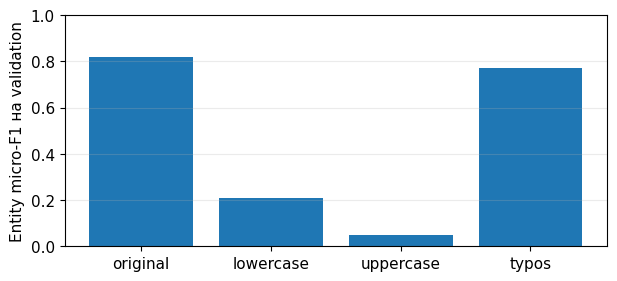

In [32]:
if '6.3' in BONUS_TASKS:
    typo_rng = random.Random(SEED)

    def add_typo(word):
        positions = [i for i in range(1, len(word) - 2)
                     if word[i].isalpha() and word[i + 1].isalpha() and word[i] != word[i + 1]]
        if len(word) >= 5 and positions and typo_rng.random() < 0.3:
            position = typo_rng.choice(positions)
            return word[:position] + word[position + 1] + word[position] + word[position + 2:]
        return word

    corrupted = {
        'lowercase': [[word.lower() for word in words] for words in val_tokens],
        'uppercase': [[word.upper() for word in words] for words in val_tokens],
        'typos': [[add_typo(word) for word in words] for words in val_tokens]
    }

    def tokenization_statistics(words_list):
        subwords = words_count = unknown = lost = truncated = 0
        for start in range(0, len(words_list), 256):
            words_batch = words_list[start:start + 256]
            encoded = tokenizer(words_batch, is_split_into_words=True, truncation=False)
            for i, words in enumerate(words_batch):
                ids = encoded.word_ids(i)
                subwords += sum(w is not None for w in ids)
                words_count += len(words)
                unknown += sum(token == tokenizer.unk_token_id for token in encoded['input_ids'][i])
                retained = {w for w in ids[:MAX_LENGTH - 1] if w is not None}
                lost += len(words) - len(retained)
                truncated += len(ids) > MAX_LENGTH
        return dict(subwords_per_word=subwords / words_count, unknown_subwords=unknown,
                    lost_words=lost, truncated_sentences=truncated)

    robustness = {'original': dict(**validation, changed_words=0,
                                    **tokenization_statistics(val_tokens))}
    for name, words_list in corrupted.items():
        assert all(len(words) == len(gold) for words, gold in zip(words_list, val_gold))
        predictions = predict_word_tags(model, words_list)
        changed_words = sum(a != b for source, target in zip(val_tokens, words_list)
                            for a, b in zip(source, target))
        robustness[name] = dict(**entity_scores(val_gold, predictions), changed_words=changed_words,
                                **tokenization_statistics(words_list))
    print(json.dumps(robustness, ensure_ascii=False, indent=2))
    for name, words_list in corrupted.items():
        print(name, ':', ' '.join(words_list[0]))
    plt.figure(figsize=(7, 3))
    plt.bar(robustness.keys(), [row['f1_micro'] for row in robustness.values()])
    plt.ylabel('Entity micro-F1 на validation')
    plt.ylim(0, 1)
    plt.grid(axis='y', alpha=0.25)
    plt.show()

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

| Вариант | F1 | Изменение, п.п. | Сабвордов на слово | Изменено слов |
|---|---:|---:|---:|---:|
| original | 0.8194 | +0.00 | 1.248 | 0 |
| lowercase | 0.2077 | -61.17 | 1.289 | 33097 |
| uppercase | 0.0481 | -77.13 | 3.320 | 165045 |
| typos | 0.7726 | -4.67 | 1.527 | 33572 |

Сильнее всего качество снизил вариант `uppercase`: F1 изменился на -77.13 п.п. При изменении регистра меняются привычные написания имён и признаки начала сущности; при опечатках переставлены две внутренние буквы с вероятностью 0.3 для подходящих слов длиной не менее 5, seed равен 0. Число слов и исходные BIO-метки сохранены во всех вариантах.

У худшего варианта получено 3.320 сабворда на слово против 1.248 у исходного текста; число потерянных слов из-за лимита выросло с 58 до 5728. Поэтому падение связано и с изменением признаков/сегментации, и с уменьшением доступного контекста; одним этим опытом эти причины не разделяются.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    import io
    import platform
    import warnings
    from torch.ao.quantization import quantize_dynamic

    cpu = torch.device('cpu')
    cpu_model = copy.deepcopy(model).cpu().eval()
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', DeprecationWarning)
        quantized_model = quantize_dynamic(cpu_model, {torch.nn.Linear}, dtype=torch.qint8, inplace=False)
    speed_batch = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True,
                            max_length=MAX_LENGTH, padding=True, return_tensors='pt')
    timings = {'fp32': [], 'int8': []}
    with torch.inference_mode():
        for _ in range(5):
            cpu_model(**speed_batch)
            quantized_model(**speed_batch)
        for repeat in range(30):
            order = [('fp32', cpu_model), ('int8', quantized_model)]
            if repeat % 2:
                order.reverse()
            for name, current_model in order:
                start = time.perf_counter()
                current_model(**speed_batch)
                timings[name].append((time.perf_counter() - start) * 1000)
    cpu_pred = predict_word_tags(cpu_model, val_tokens, dev=cpu)
    quantized_pred = predict_word_tags(quantized_model, val_tokens, dev=cpu)
    cpu_scores = entity_scores(val_gold, cpu_pred)
    quantized_scores = entity_scores(val_gold, quantized_pred)

    def serialized_size_mib(current_model):
        buffer = io.BytesIO()
        torch.save(current_model.state_dict(), buffer)
        return buffer.getbuffer().nbytes / 2**20

    quantization = dict(device=platform.processor() or 'CPU', threads=torch.get_num_threads(),
                        batch_shape=list(speed_batch['input_ids'].shape), warmup=5, repeats=30,
                        fp32=dict(**cpu_scores, mean_ms=float(np.mean(timings['fp32'])),
                                  std_ms=float(np.std(timings['fp32'])), size_mib=serialized_size_mib(cpu_model)),
                        int8=dict(**quantized_scores, mean_ms=float(np.mean(timings['int8'])),
                                  std_ms=float(np.std(timings['int8'])), size_mib=serialized_size_mib(quantized_model)),
                        speedup=float(np.mean(timings['fp32']) / np.mean(timings['int8'])),
                        delta_f1=quantized_scores['f1_micro'] - cpu_scores['f1_micro'],
                        gpu_cpu_tag_differences=sum(a != b for x, y in zip(val_pred, cpu_pred) for a, b in zip(x, y)),
                        quantized_linear_modules=sum(isinstance(module, torch.ao.nn.quantized.dynamic.Linear)
                                                     for module in quantized_model.modules()))
    print(json.dumps(quantization, ensure_ascii=False, indent=2))
    print('Падение F1 не превышает 0.01:', quantization['delta_f1'] >= -0.01)
    del cpu_model, quantized_model

{
  "device": "Intel64 Family 6 Model 151 Stepping 5, GenuineIntel",
  "threads": 4,
  "batch_shape": [
    32,
    65
  ],
  "warmup": 5,
  "repeats": 30,
  "fp32": {
    "f1_micro": 0.8193597149489824,
    "f1_macro": 0.773532038880465,
    "precision": 0.8057443193884052,
    "recall": 0.8334431630971993,
    "mean_ms": 55.651683325413615,
    "std_ms": 3.764624657113042,
    "size_mib": 111.02325248718262
  },
  "int8": {
    "f1_micro": 0.8193050609690299,
    "f1_macro": 0.7735460178512658,
    "precision": 0.8052285502174144,
    "recall": 0.8338824821526634,
    "mean_ms": 32.493683331025146,
    "std_ms": 2.2992698981999404,
    "size_mib": 104.47382736206055
  },
  "speedup": 1.712692364188737,
  "delta_f1": -5.4653979952523635e-05,
  "gpu_cpu_tag_differences": 3,
  "quantized_linear_modules": 19
}
Падение F1 не превышает 0.01: True


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

На CPU `Intel64 Family 6 Model 151 Stepping 5, GenuineIntel` с 4 потоками динамическая INT8-квантизация 19 линейных слоёв изменила среднюю задержку с 55.65 ± 3.76 до 32.49 ± 2.30 мс: отношение FP32/INT8 равно 1.71. Для обоих вариантов использован один батч формы [32, 65], 5 прогревов и 30 измерений с чередованием порядка; токенизация исключена, устройство одинаковое.

На полной validation CPU FP32 получил F1 0.8194, INT8: 0.8193, разность -0.005 п.п. Размер сериализованного `state_dict` изменился с 111.02 до 104.47 MiB: уменьшение невелико, потому что 92.1% параметров находится в эмбеддингах, которые остались FP32. Матрицы линейных слоёв дают существенную часть вычислений, но у трёхслойной модели накладные расходы квантизации и неквантизованные операции заметны, поэтому результат зависит от CPU и размера батча.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

{
  "mean": {
    "best": {
      "threshold": 0.7116168737411499,
      "precision": 0.862286872540837,
      "recall": 0.7942888522789676,
      "f1_micro": 0.8268922936199405,
      "n_predicted": 16774
    },
    "threshold_zero": {
      "threshold": 0.0,
      "precision": 0.8057443193884052,
      "recall": 0.8334431630971993,
      "f1_micro": 0.8193597149489824,
      "n_predicted": 18836
    },
    "delta_f1": 0.007532578670958134
  },
  "min": {
    "best": {
      "threshold": 0.6535905003547668,
      "precision": 0.8603959807360723,
      "recall": 0.7946732564524986,
      "f1_micro": 0.8262296953952439,
      "n_predicted": 16819
    },
    "threshold_zero": {
      "threshold": 0.0,
      "precision": 0.8057443193884052,
      "recall": 0.8334431630971993,
      "f1_micro": 0.8193597149489824,
      "n_predicted": 18836
    },
    "delta_f1": 0.0068699804462615255
  }
}
Test с порогом, выбранным только на validation: {'method': 'mean', 'threshold': 0.7116168737411499, 

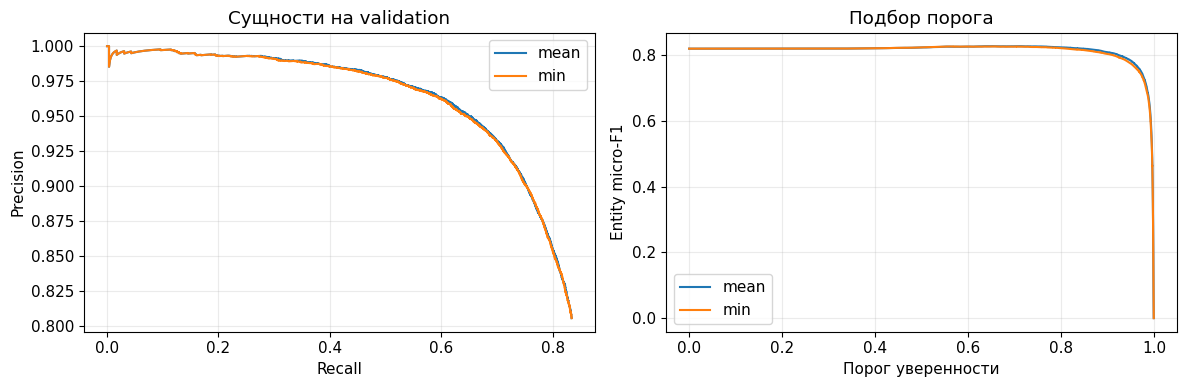

Результаты сохранены в artifacts


In [34]:
if '6.5' in BONUS_TASKS:
    confidence_pred, word_probs = predict_word_tags(model, val_tokens, return_probs=True)
    assert confidence_pred == val_pred
    scored_spans = [
        [(span, float(np.mean(probs[span[0]:span[1]])), float(np.min(probs[span[0]:span[1]])))
         for span in bio_to_spans(tags)]
        for tags, probs in zip(confidence_pred, word_probs)
    ]
    gold_sets = [set(bio_to_spans(tags)) for tags in val_gold]
    gold_count = sum(map(len, gold_sets))
    threshold_results = {}
    threshold_curves = {}
    for method, confidence_index in [('mean', 1), ('min', 2)]:
        observations = [(item[confidence_index], item[0] in gold_set)
                        for sentence_spans, gold_set in zip(scored_spans, gold_sets)
                        for item in sentence_spans]
        observations.sort(key=lambda item: item[0], reverse=True)
        confidences = np.asarray([item[0] for item in observations])
        correct = np.asarray([item[1] for item in observations], dtype=np.int64)
        cumulative = np.cumsum(correct)
        ends = np.r_[np.flatnonzero(np.diff(confidences) != 0), len(confidences) - 1]
        curve = []
        for end in ends:
            tp, n_pred = int(cumulative[end]), int(end + 1)
            curve.append(dict(threshold=float(confidences[end]), precision=tp / n_pred,
                               recall=tp / gold_count, f1_micro=2 * tp / (n_pred + gold_count),
                               n_predicted=n_pred))
        base_point = dict(threshold=0.0, precision=validation['precision'], recall=validation['recall'],
                           f1_micro=validation['f1_micro'], n_predicted=len(observations))
        curve.append(base_point)
        curve.sort(key=lambda row: row['threshold'])
        best = max(curve, key=lambda row: (row['f1_micro'], -row['threshold']))
        filtered = [spans_to_bio([item[0] for item in spans if item[confidence_index] >= best['threshold']], len(words))
                    for words, spans in zip(val_tokens, scored_spans)]
        checked_scores = entity_scores(val_gold, filtered)
        assert abs(checked_scores['f1_micro'] - best['f1_micro']) < 1e-12
        assert all(next_row['recall'] <= row['recall'] + 1e-12 for row, next_row in zip(curve, curve[1:]))
        threshold_results[method] = dict(best=best, threshold_zero=base_point,
                                         delta_f1=best['f1_micro'] - base_point['f1_micro'])
        threshold_curves[method] = curve
    chosen_method = max(threshold_results, key=lambda method: threshold_results[method]['best']['f1_micro'])
    selected_threshold = threshold_results[chosen_method]['best']['threshold']
    test_tags_with_probs, test_word_probs = predict_word_tags(model, test_tokens, return_probs=True)
    filtered_test = []
    confidence_function = np.mean if chosen_method == 'mean' else np.min
    for words, tags, probabilities in zip(test_tokens, test_tags_with_probs, test_word_probs):
        kept = [span for span in bio_to_spans(tags)
                if confidence_function(probabilities[span[0]:span[1]]) >= selected_threshold]
        filtered_test.append(spans_to_bio(kept, len(words)))
    threshold_test = dict(method=chosen_method, threshold=selected_threshold,
                          **entity_scores(test_gold, filtered_test))
    print(json.dumps(threshold_results, ensure_ascii=False, indent=2))
    print('Test с порогом, выбранным только на validation:', threshold_test)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for method, curve in threshold_curves.items():
        axes[0].plot([row['recall'] for row in curve], [row['precision'] for row in curve], label=method)
        axes[1].plot([row['threshold'] for row in curve], [row['f1_micro'] for row in curve], label=method)
    axes[0].set(xlabel='Recall', ylabel='Precision', title='Сущности на validation')
    axes[1].set(xlabel='Порог уверенности', ylabel='Entity micro-F1', title='Подбор порога')
    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

experiment_details = dict(dataset_revision=DATASET_REVISION, source_sizes=source_sizes,
                          dataset_stats=dataset_stats, split_overlap=split_overlap,
                          conversion=conversion_stats, baseline_details=baseline_details,
                          blocks=blocks, demo_shapes=demo_shapes, validation=validation,
                          train_history=history, frozen_history=frozen_history,
                          truncation=dict(train_sentences=n_truncated, lost_words=n_lost_words, checked=n_checked),
                          error_shares=error_shares, error_examples=dict(error_examples))
bonus_results = {}
for task, variable in [('6.1', 'annotation_results'), ('6.2', 'model_comparison'),
                       ('6.3', 'robustness'), ('6.4', 'quantization'), ('6.5', 'threshold_results')]:
    if task in BONUS_TASKS:
        bonus_results[task] = globals()[variable]
if '6.5' in BONUS_TASKS:
    bonus_results['6.5']['test'] = threshold_test
    (ARTIFACTS / 'threshold_curves.json').write_text(json.dumps(json_ready(threshold_curves), ensure_ascii=False), encoding='utf-8')
(ARTIFACTS / 'experiment_details.json').write_text(json.dumps(json_ready(experiment_details), ensure_ascii=False, indent=2), encoding='utf-8')
(ARTIFACTS / 'bonus_metrics.json').write_text(json.dumps(json_ready(bonus_results), ensure_ascii=False, indent=2), encoding='utf-8')
metrics['dataset_revision'] = DATASET_REVISION
metrics['bonus'] = bonus_results
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print('Результаты сохранены в artifacts')

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**

Для средней уверенности лучший validation F1 0.8269 получен при пороге 0.711617; исходный F1 при пороге 0 равен 0.8194, прибавка +0.753 п.п. Для минимальной уверенности лучший порог 0.653591, F1 0.8262, прибавка +0.687 п.п.; перебраны все различные значения уверенности спанов.

Среднее сглаживает одно неуверенное слово, минимум определяется самым слабым словом и строже относится к длинным названиям; поэтому одинаковые пороги для этих способов несопоставимы. Фильтрация только удаляет готовые спаны: число верных находок не может увеличиться, знаменатель recall постоянен, и монотонность recall дополнительно проверена кодом. Способ `mean` и порог 0.711617 выбраны только по validation; на test получены F1 0.8320, precision 0.8672, recall 0.7995, изменение F1 относительно порога 0: +0.859 п.п.